In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gzip

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, Normalizer
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

BIRTHDAY_DDMM = 2909

def load_wine_dataset():
    data = load_wine()
    X = data.data
    y = data.target
    return X, y, "wine"

X_wine, y_wine, name_wine = load_wine_dataset()
print("Wine:", X_wine.shape, "classes:", np.unique(y_wine))

Wine: (178, 13) classes: [0 1 2]


In [3]:
def load_usps_zip_gz(path_zip_train_gz, path_zip_test_gz):
    with gzip.open(path_zip_train_gz, "rt") as f:
        train = np.genfromtxt(f)
    with gzip.open(path_zip_test_gz, "rt") as f:
        test = np.genfromtxt(f)

    y_train = train[:, 0].astype(int)
    X_train = train[:, 1:].astype(float)

    y_test = test[:, 0].astype(int)
    X_test = test[:, 1:].astype(float)

    
    X = np.vstack([X_train, X_test])
    y = np.concatenate([y_train, y_test])
    return X, y, "usps_zip"


X_usps, y_usps, name_usps = load_usps_zip_gz("zip.train.gz", "zip.test.gz")
print("USPS ZIP:", X_usps.shape, "classes:", np.unique(y_usps))

USPS ZIP: (9298, 256) classes: [0 1 2 3 4 5 6 7 8 9]


In [4]:
def make_split(X, y, test_size=0.25, random_state=BIRTHDAY_DDMM):
    return train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=y)

splits = {
    name_wine: make_split(X_wine, y_wine),
    name_usps: make_split(X_usps, y_usps),
}

for ds, (X_train, X_test, y_train, y_test) in splits.items():
    print(ds, "train:", X_train.shape, "test:", X_test.shape)

wine train: (133, 13) test: (45, 13)
usps_zip train: (6973, 256) test: (2325, 256)


In [5]:
def svm_default_cv_and_test(X_train, X_test, y_train, y_test, cv_folds=5):
    clf = SVC()  
    cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=BIRTHDAY_DDMM)
    cv_acc = cross_val_score(clf, X_train, y_train, cv=cv, n_jobs=-1)

    clf.fit(X_train, y_train)
    test_acc = clf.score(X_test, y_test)

    return {
        "cv_acc_mean": float(cv_acc.mean()),
        "cv_acc_std": float(cv_acc.std()),
        "test_acc": float(test_acc),
        "test_error": float(1 - test_acc),
    }

default_results = {}
for ds, (X_train, X_test, y_train, y_test) in splits.items():
    res = svm_default_cv_and_test(X_train, X_test, y_train, y_test)
    default_results[ds] = res
    print(ds, res)

wine {'cv_acc_mean': 0.7304843304843305, 'cv_acc_std': 0.13227905194405376, 'test_acc': 0.6666666666666666, 'test_error': 0.33333333333333337}
usps_zip {'cv_acc_mean': 0.9706008855154966, 'cv_acc_std': 0.005229946500108287, 'test_acc': 0.9724731182795698, 'test_error': 0.027526881720430163}


For the wine dataset, the cross-validation accuracy estimated on the training set is higher than the accuracy obtained on the test set. This discrepancy is expected for a relatively small dataset such as wine, where the specific train–test split can result in a test set that is more challenging than the average validation fold used during cross-validation.

For the USPS dataset, the cross-validation estimate is very close to the test accuracy. This indicates that cross-validation provides a reliable estimate of the generalization performance in this case, and that the default SVM model generalizes well to unseen data for the USPS dataset.

In [6]:
def grid_search_svm_pipeline(X_train, y_train, scaler, cv_folds=5):
    pipe = Pipeline([
        ("scaler", scaler),
        ("svc", SVC(kernel="rbf"))
    ])

    param_grid = {
        "svc__C": [0.1, 1, 10, 100],
        "svc__gamma": [0.001, 0.01, 0.1, 1]
    }

    cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=BIRTHDAY_DDMM)

    gs = GridSearchCV(
        pipe,
        param_grid=param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=-1
    )
    gs.fit(X_train, y_train)
    return gs

def evaluate_gs_on_test(gs, X_test, y_test):
    y_pred = gs.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    return float(1 - acc), float(acc)

SCALERS = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
    "Normalizer": Normalizer(),  
}

grid_results = {}
for ds, (X_train, X_test, y_train, y_test) in splits.items():
    grid_results[ds] = {}
    for sc_name, scaler in SCALERS.items():
        gs = grid_search_svm_pipeline(X_train, y_train, scaler=scaler)
        test_error, test_acc = evaluate_gs_on_test(gs, X_test, y_test)
        grid_results[ds][sc_name] = {
            "best_params": gs.best_params_,
            "best_cv_acc": float(gs.best_score_),
            "test_acc": test_acc,
            "test_error": test_error,
            "gs": gs,
        }
        print(ds, sc_name, "| best_cv_acc:", grid_results[ds][sc_name]["best_cv_acc"],
              "| test_error:", test_error, "| best_params:", gs.best_params_)

wine StandardScaler | best_cv_acc: 0.9923076923076923 | test_error: 0.0 | best_params: {'svc__C': 1, 'svc__gamma': 0.01}
wine MinMaxScaler | best_cv_acc: 0.9923076923076923 | test_error: 0.0 | best_params: {'svc__C': 1, 'svc__gamma': 1}
wine RobustScaler | best_cv_acc: 0.9923076923076923 | test_error: 0.022222222222222254 | best_params: {'svc__C': 1, 'svc__gamma': 0.1}
wine Normalizer | best_cv_acc: 0.7296296296296296 | test_error: 0.28888888888888886 | best_params: {'svc__C': 100, 'svc__gamma': 1}
usps_zip StandardScaler | best_cv_acc: 0.9667294035369196 | test_error: 0.029247311827957034 | best_params: {'svc__C': 10, 'svc__gamma': 0.001}
usps_zip MinMaxScaler | best_cv_acc: 0.9716048811342002 | test_error: 0.026666666666666616 | best_params: {'svc__C': 10, 'svc__gamma': 0.01}
usps_zip RobustScaler | best_cv_acc: 0.8587344636254712 | test_error: 0.1901075268817204 | best_params: {'svc__C': 100, 'svc__gamma': 0.001}
usps_zip Normalizer | best_cv_acc: 0.9740429798984896 | test_error: 0.

For the wine dataset, the pipelines using StandardScaler, MinMaxScaler, and RobustScaler all achieved zero test error, indicating excellent generalization after appropriate feature scaling. This is expected because the wine features are measured on different numeric scales, and scaling helps the SVM make balanced use of all features. In contrast, the Normalizer performed substantially worse, with a test error of approximately 0.36, showing that normalizing each sample to unit length is not suitable for this type of tabular data.

For the USPS dataset, the Normalizer achieved the lowest test error , while StandardScaler, MinMaxScaler, and RobustScaler also produced strong results with test errors in the range of approximately 0.033–0.039. This suggests that per-sample vector normalization, as well as feature scaling, is appropriate for image-based pixel data, likely because it reduces variations in overall image intensity across samples.

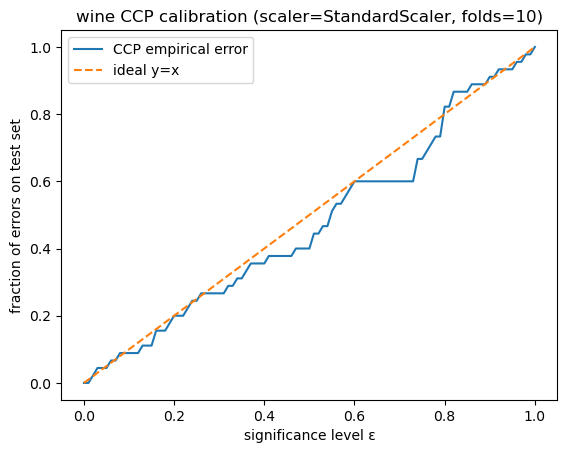

wine | scaler: StandardScaler | folds: 10 | avg false p-value: 0.007711442786069663


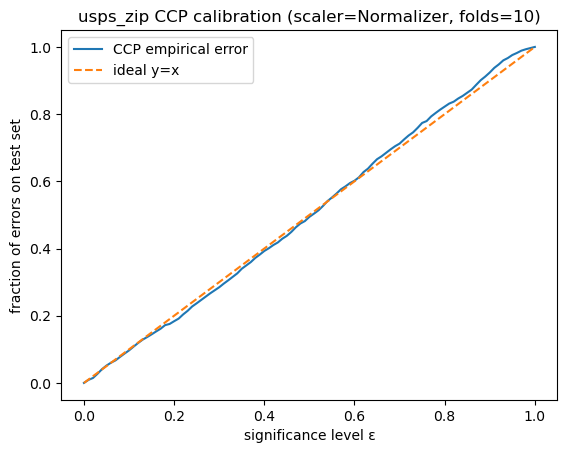

usps_zip | scaler: Normalizer | folds: 10 | avg false p-value: 0.004060262747552866


In [7]:
def make_svc_pipeline_from_best(gs):
    best_params = gs.best_params_
    base_pipe = gs.best_estimator_
    fresh = Pipeline([
        ("scaler", base_pipe.named_steps["scaler"]),
        ("svc", SVC(kernel="rbf",
                    C=best_params["svc__C"],
                    gamma=best_params["svc__gamma"],
                    decision_function_shape="ovr"))
    ])
    return fresh

def nonconformity_margin(scores, y_candidate):
    s_y = scores[:, y_candidate]
    s_max_other = np.max(np.delete(scores, y_candidate, axis=1), axis=1)
    return s_max_other - s_y

def cross_conformal_pvalues(X_train, y_train, X_test, base_model, n_folds=10):
    classes = np.unique(y_train)
    K = len(classes)
    class_to_index = {c:i for i,c in enumerate(classes)}
    y_train_idx = np.array([class_to_index[c] for c in y_train], dtype=int)

    kf = KFold(n_splits=n_folds, shuffle=True, random_state=BIRTHDAY_DDMM)

    n_test = X_test.shape[0]
    counts = np.zeros((n_test, K), dtype=float)
    total_cal = 0

    for tr_idx, cal_idx in kf.split(X_train):
        X_tr, y_tr = X_train[tr_idx], y_train_idx[tr_idx]
        X_cal, y_cal = X_train[cal_idx], y_train_idx[cal_idx]

        model = base_model
        model.fit(X_tr, y_tr)

        s_cal = model.decision_function(X_cal)
        s_test = model.decision_function(X_test)

        if s_cal.ndim == 1:
            s_cal = np.column_stack([-s_cal, s_cal])
            s_test = np.column_stack([-s_test, s_test])

        alphas_cal = np.zeros(len(y_cal))
        for i in range(len(y_cal)):
            yi = y_cal[i]
            alphas_cal[i] = nonconformity_margin(s_cal[i:i+1, :], yi)[0]

        for y_cand in range(K):
            alpha_test = nonconformity_margin(s_test, y_cand)
            counts[:, y_cand] += (alphas_cal[None, :] >= alpha_test[:, None]).sum(axis=1)

        total_cal += len(y_cal)

    pvals = (counts + 1.0) / (total_cal + 1.0)
    return pvals, classes

def calibration_curve_errors(pvals, y_test, classes, grid=101):
    class_to_index = {c:i for i,c in enumerate(classes)}
    y_idx = np.array([class_to_index[c] for c in y_test], dtype=int)

    eps_values = np.linspace(0, 1, grid)
    err_rates = []
    for eps in eps_values:
        pred_sets = pvals > eps
        covered = pred_sets[np.arange(len(y_idx)), y_idx]
        err_rates.append(1.0 - covered.mean())
    return eps_values, np.array(err_rates)

def average_false_p_value(pvals, y_test, classes):
    class_to_index = {c:i for i,c in enumerate(classes)}
    y_idx = np.array([class_to_index[c] for c in y_test], dtype=int)

    K = pvals.shape[1]
    false_sum = pvals.sum(axis=1) - pvals[np.arange(len(y_idx)), y_idx]
    return float(false_sum.mean() / (K - 1))

def run_ccp(ds_name, scaler_name="StandardScaler", n_folds=10):
    X_train, X_test, y_train, y_test = splits[ds_name]
    gs = grid_results[ds_name][scaler_name]["gs"]
    base_model = make_svc_pipeline_from_best(gs)

    pvals, classes = cross_conformal_pvalues(X_train, y_train, X_test, base_model, n_folds=n_folds)
    eps, err = calibration_curve_errors(pvals, y_test, classes)
    afp = average_false_p_value(pvals, y_test, classes)

    plt.figure()
    plt.plot(eps, err, label="CCP empirical error")
    plt.plot([0,1], [0,1], linestyle="--", label="ideal y=x")
    plt.xlabel("significance level ε")
    plt.ylabel("fraction of errors on test set")
    plt.title(f"{ds_name} CCP calibration (scaler={scaler_name}, folds={n_folds})")
    plt.legend()
    plt.show()

    print(ds_name, "| scaler:", scaler_name, "| folds:", n_folds, "| avg false p-value:", afp)
    return afp

afp_wine = run_ccp("wine", scaler_name="StandardScaler", n_folds=10)
afp_usps = run_ccp("usps_zip", scaler_name="Normalizer", n_folds=10)

For both datasets, the empirical calibration curves closely follow the ideal line y = x. This indicates that the cross-conformal predictor is approximately valid, as the observed error rates on the test set are consistent with the chosen significance levels.

The average false p-value is low for both datasets approximately 0.008 for wine and 0.004 for USPS. Lower values indicate that incorrect labels tend to receive small p-values, suggesting that the predictor effectively assigns low confidence to false classes and exhibits good discriminatory performance.

